In [2]:
# Import required libraries
import random
random.seed(42)

import torch
torch.manual_seed(42)

import numpy as np
np.random.seed(42)

import os
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


### PRE-Processing

In [4]:
# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# Define transformations for training and validation
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize to model input size
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the dataset
train_dataset = datasets.ImageFolder(root='/kaggle/input/lung-disease/Lung X-Ray Image/Lung X-Ray Image', transform=transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Count class weights to handle class imbalance
class_counts = np.bincount(train_dataset.targets)
class_weights = 1. / class_counts
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)


Using device: cuda


### Model Customization

In [5]:
# Load the EfficientNetV2 model
model = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT)

# Modify the classifier to match the number of classes
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 3)  # 3 classes

# Move the model to the device
model = model.to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth
100%|██████████| 82.7M/82.7M [00:00<00:00, 183MB/s] 


In [6]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=0.0001)

### Training Procedure

In [7]:
# Training loop
num_epochs = 10  # Adjust based on your needs
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = correct / total
    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}')


Epoch [1/10], Loss: 0.4439, Accuracy: 0.8365
Epoch [2/10], Loss: 0.2172, Accuracy: 0.9160
Epoch [3/10], Loss: 0.1626, Accuracy: 0.9413
Epoch [4/10], Loss: 0.1517, Accuracy: 0.9459
Epoch [5/10], Loss: 0.1154, Accuracy: 0.9571
Epoch [6/10], Loss: 0.0921, Accuracy: 0.9686
Epoch [7/10], Loss: 0.0721, Accuracy: 0.9761
Epoch [8/10], Loss: 0.0769, Accuracy: 0.9718
Epoch [9/10], Loss: 0.0588, Accuracy: 0.9784
Epoch [10/10], Loss: 0.0519, Accuracy: 0.9827


### Evaluation Matrix

                 precision    recall  f1-score   support

   Lung_Opacity       1.00      0.99      0.99      1125
         Normal       0.99      1.00      0.99      1250
Viral Pneumonia       1.00      1.00      1.00      1100

       accuracy                           0.99      3475
      macro avg       0.99      0.99      0.99      3475
   weighted avg       0.99      0.99      0.99      3475



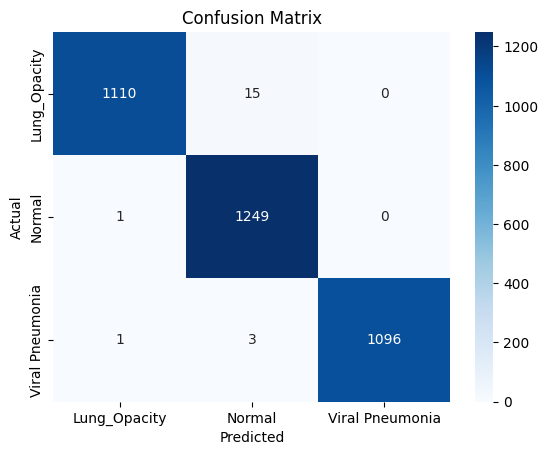

In [8]:
# Evaluation
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Classification report and confusion matrix
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

### Prediction

In [12]:
import torch
from torchvision import transforms
from PIL import Image

# Define image transformations (same as those used during training)
predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize to model input size
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the trained model (ensure it matches the one trained above)
model.eval()  # Set the model to evaluation mode

def predict_image(image_path, model, device):
    """
    Function to predict the class of a given image.
    Args:
    - image_path (str): Path to the image file.
    - model (torch.nn.Module): Trained model for prediction.
    - device (torch.device): Device (CPU/GPU) for running the prediction.
    
    Returns:
    - Predicted class label (str).
    """
    # Open the image
    image = Image.open(image_path).convert('RGB')
    
    # Apply the same transforms as used during training
    image = predict_transform(image).unsqueeze(0)  # Add batch dimension
    
    # Move image to device (GPU/CPU)
    image = image.to(device)
    
    # Forward pass through the model
    with torch.no_grad():
        output = model(image)
    
    # Get the predicted class (index with the highest value)
    _, predicted_class_idx = torch.max(output, 1)
    
    # Convert predicted class index to actual class label
    class_names = ['Lung Opacity', 'Normal', 'Viral Pneumonia']  # Modify if necessary
    predicted_class_label = class_names[predicted_class_idx.item()]
    
    return predicted_class_label

# Example usage:
image_path = '/kaggle/input/lung-disease/Lung X-Ray Image/Lung X-Ray Image/Viral Pneumonia/100.jpg'  # Specify the path to the image you want to predict
predicted_label = predict_image(image_path, model, device)
print(f'Predicted Class: {predicted_label}')


Predicted Class: Viral Pneumonia


Predicted: Viral Pneumonia, True Label: Viral Pneumonia


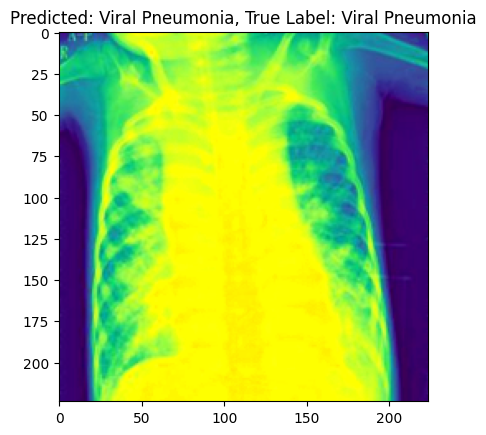

Predicted: Normal, True Label: Normal


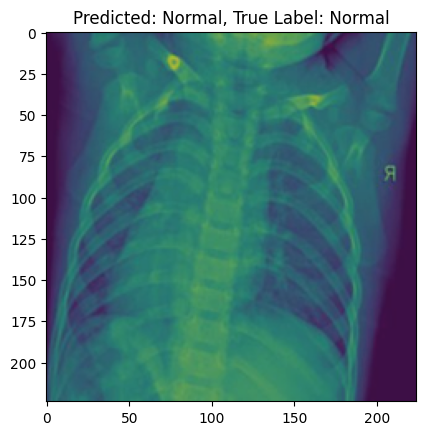

Predicted: Lung_Opacity, True Label: Lung_Opacity


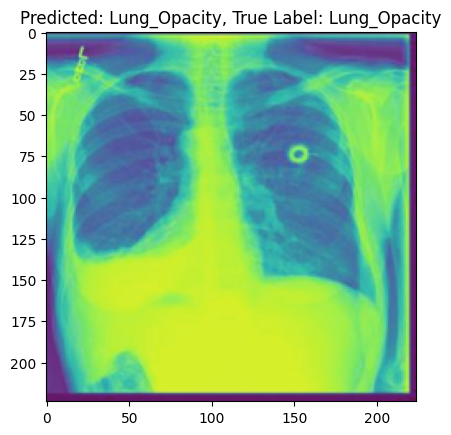

Predicted: Lung_Opacity, True Label: Lung_Opacity


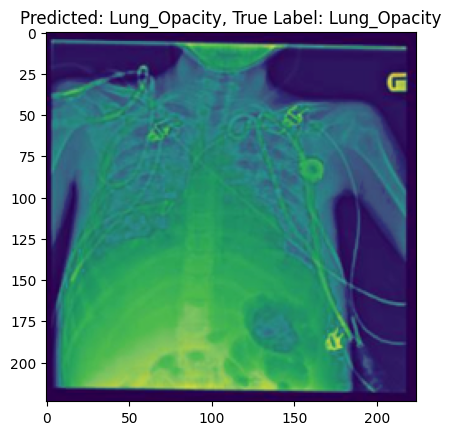

Predicted: Lung_Opacity, True Label: Lung_Opacity


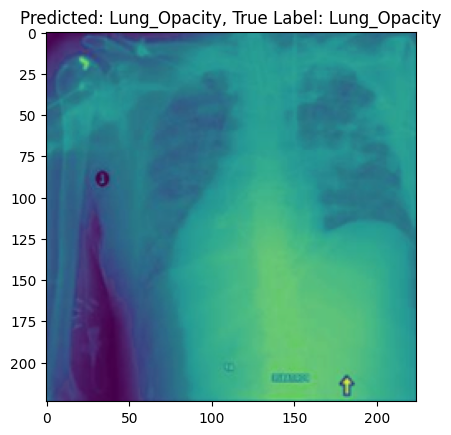

Predicted: Lung_Opacity, True Label: Lung_Opacity


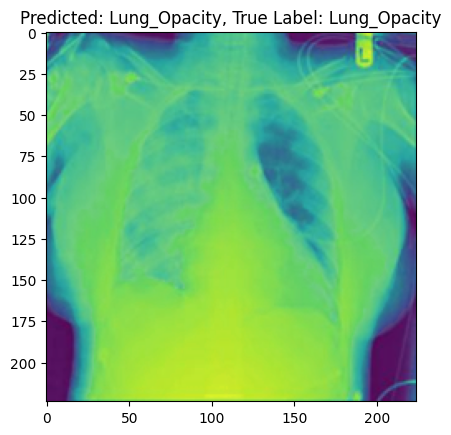

In [13]:
import os
from PIL import Image
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Define image preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize to model input size
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalization for EfficientNet
])

# Define a dataset class for loading images from the directory structure
class LungDiseaseDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = ['Lung_Opacity', 'Normal', 'Viral Pneumonia']  # Manually define the classes based on folders
        self.image_paths = []
        self.labels = []
        
        for idx, class_name in enumerate(self.classes):
            class_dir = os.path.join(root_dir, class_name)
            for img_name in os.listdir(class_dir):
                self.image_paths.append(os.path.join(class_dir, img_name))
                self.labels.append(idx)  # Class index as label
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')  # Ensure it's in RGB format
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Path to the dataset root directory
root_dir = '/kaggle/input/lung-disease/Lung X-Ray Image/Lung X-Ray Image'

# Create a dataset and dataloader
dataset = LungDiseaseDataset(root_dir, transform=preprocess)
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

# Load your model (assuming it's already loaded and modified for 3 classes)
model.eval()

# Move the model to device
model = model.to(device)

# Perform predictions
with torch.no_grad():
    for i, (inputs, labels) in enumerate(dataloader):
        inputs = inputs.to(device)  # Move inputs to the device
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)

        # Convert label and predicted class to class names
        predicted_class_name = dataset.classes[predicted.item()]
        true_class_name = dataset.classes[labels.item()]

        print(f'Predicted: {predicted_class_name}, True Label: {true_class_name}')
        
        # Display the image and prediction
        img = inputs.cpu().squeeze().permute(1, 2, 0).numpy()
        img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]  # Denormalize
        plt.imshow(img)
        plt.title(f'Predicted: {predicted_class_name}, True Label: {true_class_name}')
        plt.show()
        
        if i == 5:  # Just display 5 examples
            break


In [19]:
!pip install zennit captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.0 MB/s eta 0:00:00a 0:00:01


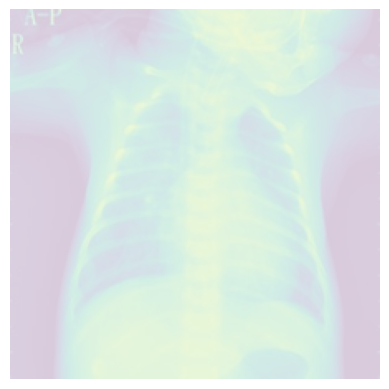

In [40]:
import torch
from torchvision import models, transforms
from captum.attr import IntegratedGradients
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Preprocessing function
def preprocess_image(image_path, device):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    return image_tensor

# Load your pre-trained model (efficientnet_v2_s)
model = models.efficientnet_v2_s(pretrained=True).eval()
model = model.to('cuda' if torch.cuda.is_available() else 'cpu')

# Integrated Gradients computation
def compute_integrated_gradients(model, input_image, target_class, device):
    ig = IntegratedGradients(model)
    attributions, delta = ig.attribute(input_image, target=target_class, return_convergence_delta=True)
    return attributions

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Updated visualization function with increased contrast
def visualize_integrated_gradients(attributions, image_path, alpha=0.8, cmap='inferno'):
    attributions = attributions.squeeze().cpu().detach().numpy()
    attributions = np.transpose(attributions, (1, 2, 0))  # Convert to HWC format

    # Scaling attributions to increase their visibility
    attributions = np.maximum(attributions, -1)  # Ensure only positive values
    attributions = attributions / np.percentile(attributions, 99)  # Scale based on 99th percentile


    # Load the original image
    image = Image.open(image_path).convert('RGB')
    image = image.resize((224, 224))  # Resize to match the attributions size

    # Display original image and heatmap overlay
    plt.imshow(image)
    plt.imshow(attributions, cmap=cmap, alpha=alpha)  # Use 'inferno' for higher contrast
    plt.axis('off')  # Hide axis
    plt.show()

# Example usage
image_path = '/kaggle/input/lung-disease/Lung X-Ray Image/Lung X-Ray Image/Viral Pneumonia/1001.jpg'  # Replace with your image path
visualize_integrated_gradients(attributions, image_path)



In [28]:
import torch
import torchvision.transforms as transforms
from zennit.torchvision import EfficientNetCanonizer
from zennit.composites import EpsilonPlus
from PIL import Image
import matplotlib.pyplot as plt

# Preprocessing function
def preprocess_image(image_path, device):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    return image_tensor

# Load pre-trained model (e.g., efficientnet_v2_s or any model)
model = models.efficientnet_v2_s(pretrained=True).eval()
model = model.to('cuda' if torch.cuda.is_available() else 'cpu')

# Define the canonizer and composite for LRP
canonizer = EfficientNetCanonizer()
composite = EpsilonPlus()  # LRP rule: EpsilonPlus

# Generate LRP heatmap
def generate_lrp_heatmap(model, image_tensor, target_class, device):
    model.zero_grad()  # Zero gradients
    output = model(image_tensor)
    output[:, target_class].backward()  # Backprop for the target class

    # Collect gradients
    gradients = image_tensor.grad.detach().cpu().numpy()[0]
    return gradients

# Visualize LRP heatmap
def visualize_heatmap(heatmap, image_path):
    heatmap = heatmap.mean(axis=0)  # Averaging across RGB channels
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min())  # Normalize

    # Load original image and overlay heatmap
    image = Image.open(image_path).convert('RGB')
    plt.imshow(image)
    plt.imshow(heatmap, cmap='jet', alpha=0.5)  # Overlay heatmap
    plt.show()

# Example usage on Kaggle
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
image_path = '/kaggle/input/lung-disease/Lung X-Ray Image/Lung X-Ray Image/Viral Pneumonia/1001.jpg'

# Preprocess image
image_tensor = preprocess_image(image_path, device)
image_tensor.requires_grad = True  # Enable gradients

# Predict class
output = model(image_tensor)
_, predicted_class = torch.max(output, 1)

# Generate LRP heatmap
lrp_heatmap = generate_lrp_heatmap(model, image_tensor, predicted_class.item(), device)

# Visualize LRP heatmap
visualize_heatmap(lrp_heatmap, image_path)


ImportError: cannot import name 'EfficientNetCanonizer' from 'zennit.torchvision' (/opt/conda/lib/python3.10/site-packages/zennit/torchvision.py)